# Wildlife AI — EfficientNet-B3 Training (Snapshot Serengeti S3)
**Tasks**: Species classification + Day/Night + Empty frame detection
**Architecture**: EfficientNet-B3 with transfer learning
**Dataset**: Snapshot Serengeti Season 3
**Purpose**: Comparison against ResNet50 baseline

## 1. Imports

In [5]:
import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from datetime import datetime
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from PIL import Image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')


Device: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
VRAM: 8.6 GB


In [ ]:
import os
import glob

# Search for the mapping file
results = glob.glob(r'C:\Users\dippe\**\image_label_mapping.csv', recursive=True)
for r in results:
    print(r)

## 2. Configuration

In [6]:
# ============================================================
# UPDATE THESE PATHS
# ============================================================
IMAGES_DIR = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\PROJECT\data'
JSON_PATH  = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\Datset\Serenegetijson\SnapshotSerengetiS03.json'
OUTPUT_DIR = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\Wildlife-AI-Monitoring-System-using-Camera-trap-images\models\trained_models'
DATA_DIR = r'C:\Users\dippe\Desktop\University of Botswana\Semester 8\FINALYEARPROJECT\wildlife-ai-system\data\serengeti'
# ============================================================

TARGET_SPECIES = {
    0:  'empty',
    5:  'zebra',
    8:  'hyenaspotted',
    10: 'impala',
    13: 'giraffe',
    18: 'wildebeest',
    19: 'leopard',
    21: 'lion',
    24: 'cheetah',
    39: 'lion',
}

MAX_PER_CLASS = {
    'empty':        3000,
    'zebra':        3000,
    'wildebeest':   3000,
    'giraffe':      3000,
    'impala':       2000,
    'lion':         1500,
    'hyenaspotted': 1000,
    'cheetah':       245,
    'leopard':        29,
}

# EfficientNet-B3 uses 300x300 input (vs 224x224 for ResNet50)
IMG_SIZE      = 300
BATCH_SIZE    = 24   # slightly smaller due to larger image size
NUM_EPOCHS    = 25
LEARNING_RATE = 1e-4
VAL_SPLIT     = 0.2
WARMUP_EPOCHS = 3
DAY_START     = 6
DAY_END       = 18

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(DATA_DIR, exist_ok=True)
print('Configg ready.')
print(f'Image size: {IMG_SIZE}x{IMG_SIZE} (EfficientNet-B3 native resolution)')


Configg ready.
Image size: 300x300 (EfficientNet-B3 native resolution)


## 3. Load Saved Mapping
Reuses the image_label_mapping.csv from ResNet training — no need to reload the full JSON.

In [10]:
mapping_path = os.path.join(DATA_DIR, 'image_label_mapping.csv')

if os.path.exists(mapping_path):
    print('Loading saved mapping...')
    balanced_df = pd.read_csv(mapping_path)
    print(f'Loaded {len(balanced_df)} records')
    print(balanced_df['species'].value_counts())
else:
    print('Mapping not found — rebuilding from JSON...')
    # Load JSON and rebuild (copy from ResNet notebook Section 3-4)
    raise FileNotFoundError('Run the ResNet notebook first to generate image_label_mapping.csv')


Loading saved mapping...
Loaded 16774 records
species
empty           3000
zebra           3000
wildebeest      3000
giraffe         3000
impala          2000
lion            1500
hyenaspotted    1000
cheetah          245
leopard           29
Name: count, dtype: int64


## 4. Label Encoding

In [11]:
# Load label map from ResNet training
with open(os.path.join(OUTPUT_DIR, 'label_map.json'), 'r') as f:
    label_map = json.load(f)

species_classes = label_map['species_classes']
tod_classes     = label_map['tod_classes']
tod2idx         = {t: i for i, t in enumerate(tod_classes)}
num_species     = len(species_classes)

balanced_df['species_label'] = balanced_df['species'].map(label_map['species2idx'])
balanced_df['tod_label']     = balanced_df['time_of_day'].map(tod2idx).fillna(2).astype(int)

print(f'Species classes ({num_species}): {species_classes}')


Species classes (9): ['cheetah', 'empty', 'giraffe', 'hyenaspotted', 'impala', 'leopard', 'lion', 'wildebeest', 'zebra']


## 5. Train/Val Split

In [12]:
train_df, val_df = train_test_split(
    balanced_df,
    test_size=VAL_SPLIT,
    stratify=balanced_df['species_label'],
    random_state=42   # same seed = same split as ResNet for fair comparison
)
train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
print(f'Train: {len(train_df)} | Val: {len(val_df)}')
print('Note: Same random_state=42 as ResNet ensures identical train/val split for fair comparison.')


Train: 13419 | Val: 3355
Note: Same random_state=42 as ResNet ensures identical train/val split for fair comparison.


## 6. Dataset & DataLoaders
EfficientNet-B3 uses 300x300 input and different normalization stats.

In [13]:
# EfficientNet normalization (same as ImageNet but different from ResNet convention)
MEAN = [0.485, 0.456, 0.406]
STD  = [0.229, 0.224, 0.225]

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.4, contrast=0.4, saturation=0.3, hue=0.1),
    transforms.RandomGrayscale(p=0.1),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

val_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

class WildlifeDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df        = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        try:
            image = Image.open(row['image_path']).convert('RGB')
        except Exception:
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (0, 0, 0))
        if self.transform:
            image = self.transform(image)
        return {
            'image':         image,
            'species_label': torch.tensor(int(row['species_label']), dtype=torch.long),
            'tod_label':     torch.tensor(int(row['tod_label']),     dtype=torch.long),
            'is_empty':      torch.tensor(float(row['is_empty']),    dtype=torch.float),
        }

train_dataset = WildlifeDataset(train_df, transform=train_transforms)
val_dataset   = WildlifeDataset(val_df,   transform=val_transforms)

# Weighted sampler
class_counts   = train_df['species_label'].value_counts().sort_index().values
class_weights  = 1.0 / class_counts
sample_weights = class_weights[train_df['species_label'].values]
sampler = WeightedRandomSampler(sample_weights, len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, sampler=sampler,  num_workers=0, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False,    num_workers=0, pin_memory=True)

print(f'Train batches: {len(train_loader)} | Val batches: {len(val_loader)}')


Train batches: 560 | Val batches: 140


## 7. Model — Multi-task EfficientNet-B3
Key differences from ResNet50:
- Compound scaling: width, depth and resolution scaled together
- Squeeze-and-Excitation (SE) blocks: channel attention mechanism
- 12M parameters vs ResNet50's 25.6M — more efficient
- Native 300x300 input vs ResNet50's 224x224

In [14]:
class WildlifeEfficientNet(nn.Module):
    """
    EfficientNet-B3 backbone with 3 output heads:
      - species_head:  N-class species classification
      - tod_head:      3-class time-of-day (day/night/unknown)
      - empty_head:    binary empty frame detection

    Key difference from ResNet: EfficientNet uses Squeeze-and-Excitation
    blocks which apply channel-wise attention — the model learns WHICH
    feature channels are most important for each prediction.
    This is particularly useful for camera trap images where the animal
    may occupy a small portion of the frame.
    """
    def __init__(self, num_species):
        super().__init__()
        backbone = efficientnet_b3(weights=EfficientNet_B3_Weights.IMAGENET1K_V1)
        in_features = backbone.classifier[1].in_features  # 1536 for B3
        backbone.classifier = nn.Identity()  # remove original classifier
        self.backbone = backbone

        self.species_head = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(in_features, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, num_species),
        )
        self.tod_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Linear(128, 3),
        )
        self.empty_head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(in_features, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        features = self.backbone(x)
        return {
            'species': self.species_head(features),
            'tod':     self.tod_head(features),
            'empty':   self.empty_head(features).squeeze(1),
        }

model = WildlifeEfficientNet(num_species=num_species).to(device)
print(f'Model ready — {num_species} species classes')

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
print(f'Total parameters: {total_params / 1e6:.1f}M')
print(f'(ResNet50 has ~25.6M for comparison)')

# Freeze backbone for warmup
for param in model.backbone.parameters():
    param.requires_grad = False
print(f'Backbone frozen for {WARMUP_EPOCHS} warmup epochs.')


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to C:\Users\dippe/.cache\torch\hub\checkpoints\efficientnet_b3_rwightman-b3899882.pth
100%|█████████████████████████████████████████████████████████████████████████████| 47.2M/47.2M [00:47<00:00, 1.05MB/s]


Model ready — 9 species classes
Total parameters: 11.8M
(ResNet50 has ~25.6M for comparison)
Backbone frozen for 3 warmup epochs.


## 8. Loss Functions & Optimizer

In [15]:
class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, reduction='mean'):
        super().__init__()
        self.gamma     = gamma
        self.reduction = reduction

    def forward(self, inputs, targets):
        ce_loss = nn.functional.cross_entropy(inputs, targets, reduction='none')
        pt      = torch.exp(-ce_loss)
        focal   = ((1 - pt) ** self.gamma) * ce_loss
        return focal.mean() if self.reduction == 'mean' else focal.sum()

species_loss_fn = FocalLoss(gamma=2.0)
tod_loss_fn     = nn.CrossEntropyLoss()
empty_loss_fn   = nn.BCEWithLogitsLoss()

W_SPECIES = 1.0
W_TOD     = 0.3
W_EMPTY   = 0.5

optimizer = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LEARNING_RATE, weight_decay=1e-4
)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)
print('Loss functions and optimizer ready.')


Loss functions and optimizer ready.


## 9. Training Loop

In [16]:
def run_epoch(loader, training=True):
    model.train() if training else model.eval()
    total_loss      = 0
    species_correct = 0
    tod_correct     = 0
    empty_correct   = 0
    total           = 0

    ctx = torch.enable_grad() if training else torch.no_grad()
    with ctx:
        for batch in tqdm(loader, leave=False):
            images       = batch['image'].to(device)
            sp_labels    = batch['species_label'].to(device)
            tod_labels   = batch['tod_label'].to(device)
            empty_labels = batch['is_empty'].to(device)

            outputs = model(images)

            loss_sp  = species_loss_fn(outputs['species'], sp_labels)
            loss_tod = tod_loss_fn(outputs['tod'], tod_labels)
            loss_emp = empty_loss_fn(outputs['empty'], empty_labels)
            loss     = W_SPECIES * loss_sp + W_TOD * loss_tod + W_EMPTY * loss_emp

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss      += loss.item() * len(images)
            total           += len(images)
            species_correct += (outputs['species'].argmax(1) == sp_labels).sum().item()
            tod_correct     += (outputs['tod'].argmax(1) == tod_labels).sum().item()
            empty_pred       = (torch.sigmoid(outputs['empty']) > 0.5).float()
            empty_correct   += (empty_pred == empty_labels).sum().item()

    return {
        'loss':        total_loss / total,
        'species_acc': species_correct / total,
        'tod_acc':     tod_correct / total,
        'empty_acc':   empty_correct / total,
    }

history      = {'train': [], 'val': []}
best_val_acc = 0.0
history_path = os.path.join(OUTPUT_DIR, 'efficientnet_training_history.json')

print('Starting EfficientNet-B3 training...')
print(f'Warmup: {WARMUP_EPOCHS} epochs (heads only) -> then full fine-tuning')
print('-' * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    if epoch == WARMUP_EPOCHS + 1:
        print('Unfreezing backbone — starting full fine-tuning...')
        for param in model.backbone.parameters():
            param.requires_grad = True
        optimizer = optim.AdamW(
            model.parameters(),
            lr=LEARNING_RATE * 0.1,
            weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS
        )

    train_metrics = run_epoch(train_loader, training=True)
    val_metrics   = run_epoch(val_loader,   training=False)
    scheduler.step()

    history['train'].append(train_metrics)
    history['val'].append(val_metrics)

    # Save history after every epoch
    with open(history_path, 'w') as f:
        json.dump(history, f)

    print(
        f"Epoch {epoch:02d}/{NUM_EPOCHS} | "
        f"Train Loss: {train_metrics['loss']:.4f} | "
        f"Val Loss: {val_metrics['loss']:.4f} | "
        f"Val Species: {val_metrics['species_acc']:.3f} | "
        f"Val Empty: {val_metrics['empty_acc']:.3f} | "
        f"Val ToD: {val_metrics['tod_acc']:.3f}"
    )

    if val_metrics['species_acc'] > best_val_acc:
        best_val_acc = val_metrics['species_acc']
        torch.save({
            'epoch':                epoch,
            'model_state_dict':     model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_species_acc':      best_val_acc,
            'num_species':          num_species,
            'species_classes':      species_classes,
            'tod_classes':          tod_classes,
        }, os.path.join(OUTPUT_DIR, 'efficientnet_b3_serengeti_best.pth'))
        print(f'  -> Best model saved (val acc: {best_val_acc:.3f})')

print(f'Training complete! Best val accuracy: {best_val_acc:.3f}')


Starting EfficientNet-B3 training...
Warmup: 3 epochs (heads only) -> then full fine-tuning
----------------------------------------------------------------------


Epoch 01/25 | Train Loss: 1.2909 | Val Loss: 0.7289 | Val Species: 0.751 | Val Empty: 0.895 | Val ToD: 0.952
  -> Best model saved (val acc: 0.751)


Epoch 02/25 | Train Loss: 0.8111 | Val Loss: 0.6013 | Val Species: 0.775 | Val Empty: 0.901 | Val ToD: 0.954
  -> Best model saved (val acc: 0.775)


Epoch 03/25 | Train Loss: 0.7453 | Val Loss: 0.5453 | Val Species: 0.787 | Val Empty: 0.914 | Val ToD: 0.954
  -> Best model saved (val acc: 0.787)
Unfreezing backbone — starting full fine-tuning...


Epoch 04/25 | Train Loss: 0.6070 | Val Loss: 0.4421 | Val Species: 0.827 | Val Empty: 0.932 | Val ToD: 0.954
  -> Best model saved (val acc: 0.827)


Epoch 05/25 | Train Loss: 0.4893 | Val Loss: 0.3919 | Val Species: 0.840 | Val Empty: 0.935 | Val ToD: 0.956
  -> Best model saved (val acc: 0.840)


... (16 outputs left out)

Epoch 22/25 | Train Loss: 0.2226 | Val Loss: 0.2466 | Val Species: 0.895 | Val Empty: 0.956 | Val ToD: 0.959
  -> Best model saved (val acc: 0.895)


Epoch 23/25 | Train Loss: 0.2246 | Val Loss: 0.2449 | Val Species: 0.890 | Val Empty: 0.958 | Val ToD: 0.958


Epoch 24/25 | Train Loss: 0.2374 | Val Loss: 0.2471 | Val Species: 0.892 | Val Empty: 0.959 | Val ToD: 0.958


Epoch 25/25 | Train Loss: 0.2348 | Val Loss: 0.2481 | Val Species: 0.890 | Val Empty: 0.959 | Val ToD: 0.959
Training complete! Best val accuracy: 0.895


## 10. Training Curves

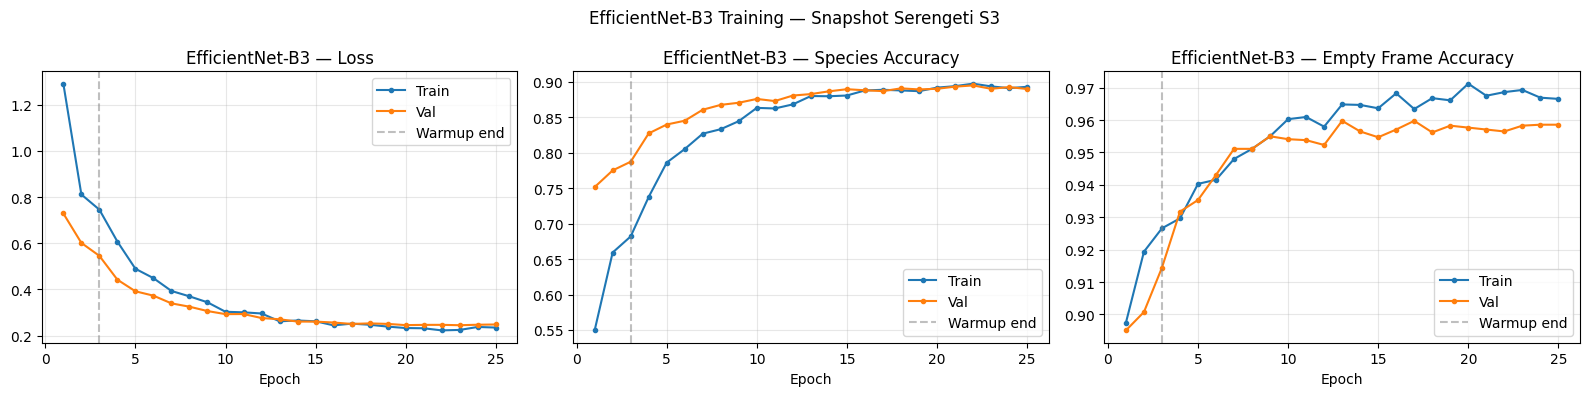

Training curves saved.


In [17]:
# Load history (works even after kernel reset)
with open(history_path, 'r') as f:
    history = json.load(f)

epochs = list(range(1, len(history['val']) + 1))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics = ['loss', 'species_acc', 'empty_acc']
titles  = ['Loss', 'Species Accuracy', 'Empty Frame Accuracy']

for ax, metric, title in zip(axes, metrics, titles):
    ax.plot(epochs, [m[metric] for m in history['train']], label='Train', marker='o', markersize=3)
    ax.plot(epochs, [m[metric] for m in history['val']],   label='Val',   marker='o', markersize=3)
    ax.axvline(x=3, color='gray', linestyle='--', alpha=0.5, label='Warmup end')
    ax.set_title(f'EfficientNet-B3 — {title}')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.suptitle('EfficientNet-B3 Training — Snapshot Serengeti S3', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnet_training_curves.png'), dpi=150)
plt.show()
print('Training curves saved.')


## 11. Evaluation

In [18]:
checkpoint = torch.load(
    os.path.join(OUTPUT_DIR, 'efficientnet_b3_serengeti_best.pth'),
    map_location=device, weights_only=False
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f'Loaded best model from epoch {checkpoint["epoch"]}')

all_sp_preds, all_sp_labels = [], []

with torch.no_grad():
    for batch in tqdm(val_loader):
        images    = batch['image'].to(device)
        sp_labels = batch['species_label']
        outputs   = model(images)
        preds     = outputs['species'].argmax(1).cpu()
        all_sp_preds.extend(preds.numpy())
        all_sp_labels.extend(sp_labels.numpy())

print('\nClassification Report:')
print(classification_report(
    all_sp_labels, all_sp_preds,
    target_names=species_classes,
    zero_division=0
))


Loaded best model from epoch 22


100%|████████████████████████████████████████████████████████████████████████████████| 140/140 [05:36<00:00,  2.40s/it]


Classification Report:
              precision    recall  f1-score   support

     cheetah       0.82      0.94      0.88        49
       empty       0.89      0.90      0.89       600
     giraffe       0.95      0.92      0.93       600
hyenaspotted       0.86      0.93      0.89       200
      impala       0.96      0.95      0.95       400
     leopard       1.00      0.50      0.67         6
        lion       0.91      0.95      0.93       300
  wildebeest       0.82      0.89      0.85       600
       zebra       0.90      0.80      0.85       600

    accuracy                           0.89      3355
   macro avg       0.90      0.86      0.87      3355
weighted avg       0.90      0.89      0.89      3355



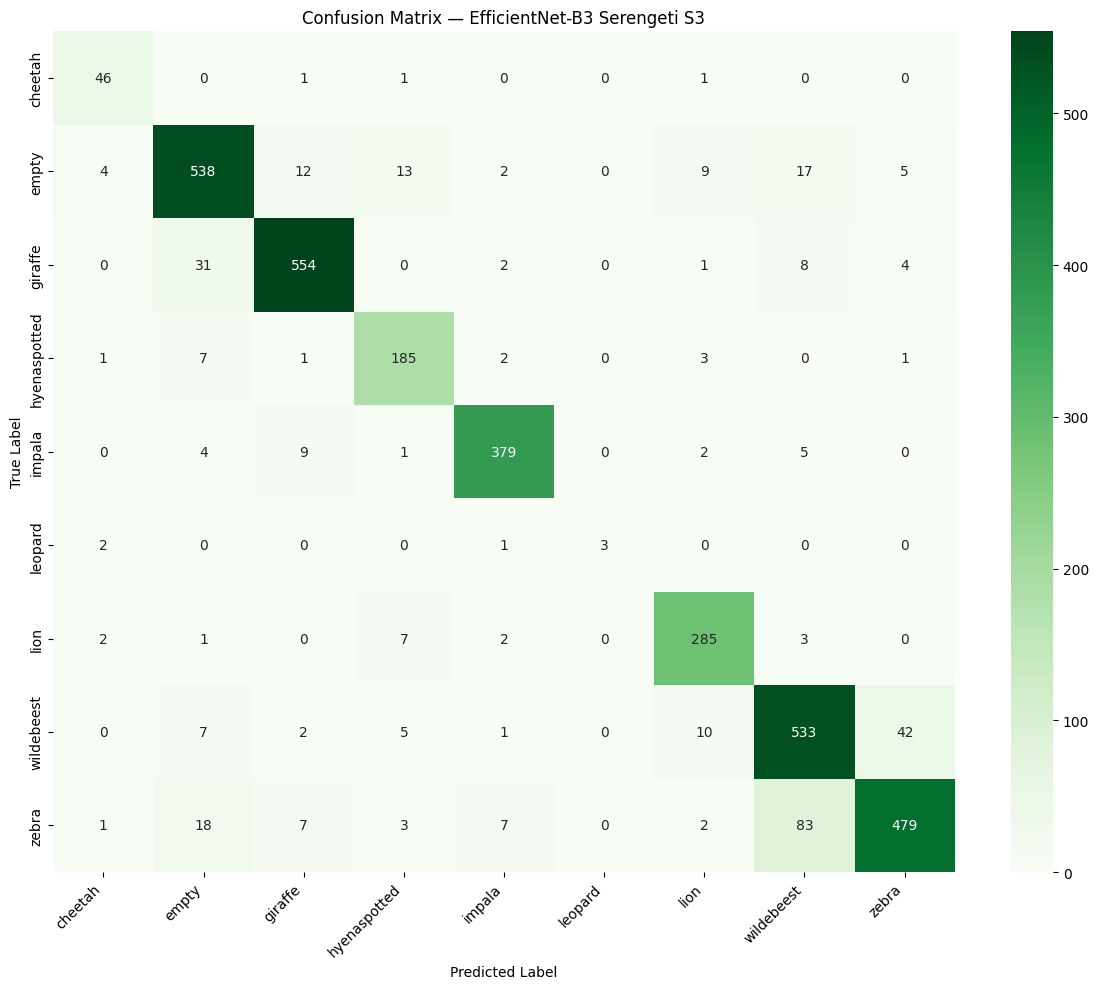

In [19]:
cm = confusion_matrix(all_sp_labels, all_sp_preds)
plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=species_classes, yticklabels=species_classes)
plt.title('Confusion Matrix — EfficientNet-B3 Serengeti S3')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnet_confusion_matrix.png'), dpi=150)
plt.show()


## 12. Side-by-Side Comparison with ResNet50

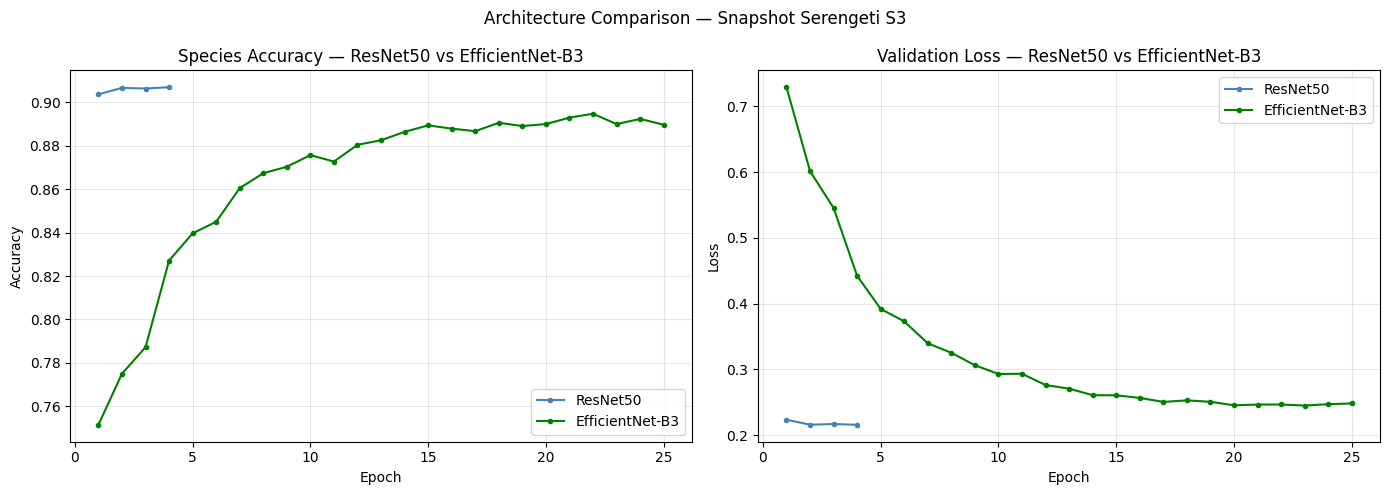

Comparison chart saved.


In [20]:
# Load ResNet50 history for comparison
resnet_history_path = os.path.join(OUTPUT_DIR, 'training_history.json')

if os.path.exists(resnet_history_path):
    with open(resnet_history_path, 'r') as f:
        resnet_history = json.load(f)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Species accuracy comparison
    en_epochs = list(range(1, len(history['val']) + 1))
    rn_epochs = list(range(1, len(resnet_history['val']) + 1))

    axes[0].plot(rn_epochs, [m['species_acc'] for m in resnet_history['val']], label='ResNet50', marker='o', markersize=3, color='steelblue')
    axes[0].plot(en_epochs, [m['species_acc'] for m in history['val']],        label='EfficientNet-B3', marker='o', markersize=3, color='green')
    axes[0].set_title('Species Accuracy — ResNet50 vs EfficientNet-B3')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss comparison
    axes[1].plot(rn_epochs, [m['loss'] for m in resnet_history['val']], label='ResNet50', marker='o', markersize=3, color='steelblue')
    axes[1].plot(en_epochs, [m['loss'] for m in history['val']],        label='EfficientNet-B3', marker='o', markersize=3, color='green')
    axes[1].set_title('Validation Loss — ResNet50 vs EfficientNet-B3')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.suptitle('Architecture Comparison — Snapshot Serengeti S3', fontsize=12)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, 'architecture_comparison.png'), dpi=150)
    plt.show()
    print('Comparison chart saved.')
else:
    print('ResNet50 history not found. Run ResNet notebook first to generate comparison.')


## 13. Save Model Info

In [21]:
total_params = sum(p.numel() for p in model.parameters())

model_info = {
    'architecture':          'EfficientNet-B3',
    'dataset':               'Snapshot Serengeti S3',
    'num_species':           num_species,
    'species_classes':       species_classes,
    'tod_classes':           tod_classes,
    'img_size':              IMG_SIZE,
    'batch_size':            BATCH_SIZE,
    'best_val_species_acc':  best_val_acc,
    'total_parameters_M':    round(total_params / 1e6, 1),
    'total_training_images': len(train_df),
    'total_val_images':      len(val_df),
    'checkpoint':            'efficientnet_b3_serengeti_best.pth',
    'loss_function':         'FocalLoss (gamma=2.0) for species, CrossEntropy for ToD, BCEWithLogits for empty',
}
with open(os.path.join(OUTPUT_DIR, 'efficientnet_model_info.json'), 'w') as f:
    json.dump(model_info, f, indent=2)

print('Model info saved.')
print(json.dumps(model_info, indent=2))


Model info saved.
{
  "architecture": "EfficientNet-B3",
  "dataset": "Snapshot Serengeti S3",
  "num_species": 9,
  "species_classes": [
    "cheetah",
    "empty",
    "giraffe",
    "hyenaspotted",
    "impala",
    "leopard",
    "lion",
    "wildebeest",
    "zebra"
  ],
  "tod_classes": [
    "day",
    "night",
    "unknown"
  ],
  "img_size": 300,
  "batch_size": 24,
  "best_val_species_acc": 0.8947839046199701,
  "total_parameters_M": 11.8,
  "total_training_images": 13419,
  "total_val_images": 3355,
  "checkpoint": "efficientnet_b3_serengeti_best.pth",
  "loss_function": "FocalLoss (gamma=2.0) for species, CrossEntropy for ToD, BCEWithLogits for empty"
}


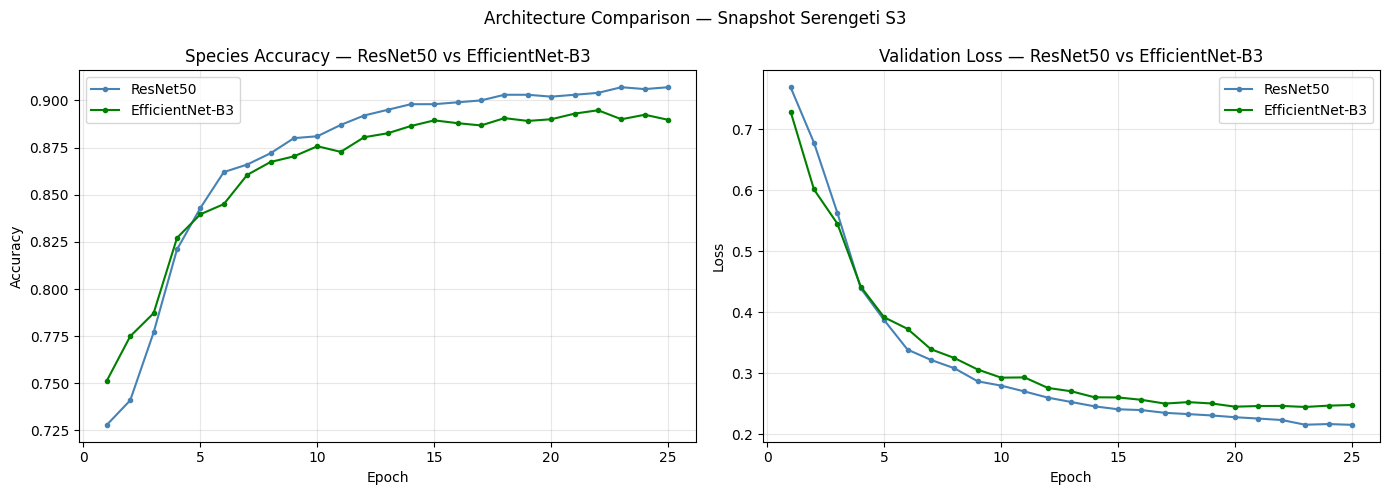

Comparison chart saved!


In [7]:
resnet_val = [
    {'loss': 0.7689, 'species_acc': 0.728, 'empty_acc': 0.885},
    {'loss': 0.6779, 'species_acc': 0.741, 'empty_acc': 0.900},
    {'loss': 0.5630, 'species_acc': 0.777, 'empty_acc': 0.916},
    {'loss': 0.4395, 'species_acc': 0.821, 'empty_acc': 0.931},
    {'loss': 0.3872, 'species_acc': 0.843, 'empty_acc': 0.940},
    {'loss': 0.3389, 'species_acc': 0.862, 'empty_acc': 0.942},
    {'loss': 0.3220, 'species_acc': 0.866, 'empty_acc': 0.945},
    {'loss': 0.3084, 'species_acc': 0.872, 'empty_acc': 0.949},
    {'loss': 0.2869, 'species_acc': 0.880, 'empty_acc': 0.949},
    {'loss': 0.2799, 'species_acc': 0.881, 'empty_acc': 0.951},
    {'loss': 0.2703, 'species_acc': 0.887, 'empty_acc': 0.956},
    {'loss': 0.2602, 'species_acc': 0.892, 'empty_acc': 0.957},
    {'loss': 0.2530, 'species_acc': 0.895, 'empty_acc': 0.957},
    {'loss': 0.2459, 'species_acc': 0.898, 'empty_acc': 0.962},
    {'loss': 0.2411, 'species_acc': 0.898, 'empty_acc': 0.959},
    {'loss': 0.2398, 'species_acc': 0.899, 'empty_acc': 0.960},
    {'loss': 0.2353, 'species_acc': 0.900, 'empty_acc': 0.962},
    {'loss': 0.2332, 'species_acc': 0.903, 'empty_acc': 0.963},
    {'loss': 0.2310, 'species_acc': 0.903, 'empty_acc': 0.963},
    {'loss': 0.2281, 'species_acc': 0.902, 'empty_acc': 0.963},
    {'loss': 0.2259, 'species_acc': 0.903, 'empty_acc': 0.961},
    {'loss': 0.2235, 'species_acc': 0.904, 'empty_acc': 0.964},
    {'loss': 0.2158, 'species_acc': 0.907, 'empty_acc': 0.965},
    {'loss': 0.2169, 'species_acc': 0.906, 'empty_acc': 0.966},
    {'loss': 0.2156, 'species_acc': 0.907, 'empty_acc': 0.966},
]

# Load EfficientNet history
with open(os.path.join(OUTPUT_DIR, 'efficientnet_training_history.json'), 'r') as f:
    en_history = json.load(f)

epochs = list(range(1, 26))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Species accuracy
axes[0].plot(epochs, [m['species_acc'] for m in resnet_val], label='ResNet50', marker='o', markersize=3, color='steelblue')
axes[0].plot(epochs, [m['species_acc'] for m in en_history['val']], label='EfficientNet-B3', marker='o', markersize=3, color='green')
axes[0].set_title('Species Accuracy — ResNet50 vs EfficientNet-B3')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(epochs, [m['loss'] for m in resnet_val], label='ResNet50', marker='o', markersize=3, color='steelblue')
axes[1].plot(epochs, [m['loss'] for m in en_history['val']], label='EfficientNet-B3', marker='o', markersize=3, color='green')
axes[1].set_title('Validation Loss — ResNet50 vs EfficientNet-B3')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Architecture Comparison — Snapshot Serengeti S3', fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'architecture_comparison.png'), dpi=150)
plt.show()
print('Comparison chart saved!')